<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/%20%20%20models/DenseNet169.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MUFSAL - DenseNet-169 (same structure as the team's notebooks)

Runtime > Change runtime type > **T4 GPU**, then Runtime > **Run all**.

In [1]:
import torch
print(torch.cuda.is_available())

True


## Dataset

In [2]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [3]:
!ls {path}

auto_test  test  train	val


## Pre-processing (Denoise + resize + normalize) and loaders

In [4]:
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

base = path

# Noise reduction (Gaussian blur) + contrast enhancement (CLAHE)
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))
        g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

USE_DENOISE = True   # set to False to train WITHOUT Denoise and compare the results

pre = [Denoise()] if USE_DENOISE else []
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# val / test: no augmentation
tf = transforms.Compose(pre + [
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    norm,
])

# train: with augmentation
train_tf = transforms.Compose(pre + [
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)

train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


## Class weights (Grade 4 is rare)

In [5]:
from collections import Counter

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("train counts:", dict(sorted(counts.items())))
print("class weights:", [round(w, 2) for w in weights])

train counts: {0: 2286, 1: 1046, 2: 1516, 3: 757, 4: 173}
class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


## Model: DenseNet-169 (ImageNet pre-trained)

In [6]:
import torch.nn as nn
from torchvision import models

device = "cuda" if torch.cuda.is_available() else "cpu"

model = models.densenet169(weights=models.DenseNet169_Weights.IMAGENET1K_V1)
num_ftrs = model.classifier.in_features
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(num_ftrs, 5))
model = model.to(device)

print("Output features:", model.classifier)

Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 137MB/s]


Output features: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1664, out_features=5, bias=True)
)


## Training (prints Train/Val loss and accuracy after every epoch)

In [7]:
import copy
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

num_epochs = 25
patience = 6          # early stopping
best_val_acc, bad_epochs = 0.0, 0
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 35)

    # --- train ---
    model.train()
    running_loss, running_corrects = 0.0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += (preds == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = running_corrects / len(train_loader.dataset)
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

    # --- validation ---
    model.eval()
    val_loss, val_corrects = 0.0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += (preds == labels).sum().item()

    val_loss_epoch = val_loss / len(val_loader.dataset)
    val_acc_epoch = val_corrects / len(val_loader.dataset)
    print(f"Val Loss:   {val_loss_epoch:.4f} | Val Acc:   {val_acc_epoch:.4f}")

    scheduler.step(val_loss_epoch)

    # keep the best model (chosen on VALIDATION, not test)
    if val_acc_epoch > best_val_acc:
        best_val_acc = val_acc_epoch
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), "best_densenet169_knee.pth")
        bad_epochs = 0
        print("Best model saved.")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("Early stopping.")
            break

model.load_state_dict(best_model_wts)
print(f"\nBest Validation Accuracy: {best_val_acc:.4f}")


Epoch 1/25
-----------------------------------
Train Loss: 1.1945 | Train Acc: 0.4323
Val Loss:   0.9460 | Val Acc:   0.5860
Best model saved.

Epoch 2/25
-----------------------------------
Train Loss: 0.8636 | Train Acc: 0.5708
Val Loss:   0.9065 | Val Acc:   0.5993
Best model saved.

Epoch 3/25
-----------------------------------
Train Loss: 0.7707 | Train Acc: 0.6211
Val Loss:   0.9018 | Val Acc:   0.5872

Epoch 4/25
-----------------------------------
Train Loss: 0.6901 | Train Acc: 0.6471
Val Loss:   0.7834 | Val Acc:   0.6622
Best model saved.

Epoch 5/25
-----------------------------------
Train Loss: 0.6210 | Train Acc: 0.6930
Val Loss:   0.8538 | Val Acc:   0.6332

Epoch 6/25
-----------------------------------
Train Loss: 0.5806 | Train Acc: 0.7049
Val Loss:   0.9120 | Val Acc:   0.6356

Epoch 7/25
-----------------------------------
Train Loss: 0.5336 | Train Acc: 0.7368
Val Loss:   0.8592 | Val Acc:   0.6356

Epoch 8/25
-----------------------------------
Train Loss: 0.38

## Final evaluation on the TEST set

Test accuracy  : 0.6630
Macro F1       : 0.6775
Quadratic kappa: 0.8324

              precision    recall  f1-score   support

        KL-0      0.754     0.809     0.780       639
        KL-1      0.333     0.429     0.375       296
        KL-2      0.749     0.528     0.619       447
        KL-3      0.810     0.767     0.788       223
        KL-4      0.746     0.922     0.825        51

    accuracy                          0.663      1656
   macro avg      0.679     0.691     0.678      1656
weighted avg      0.685     0.663     0.667      1656



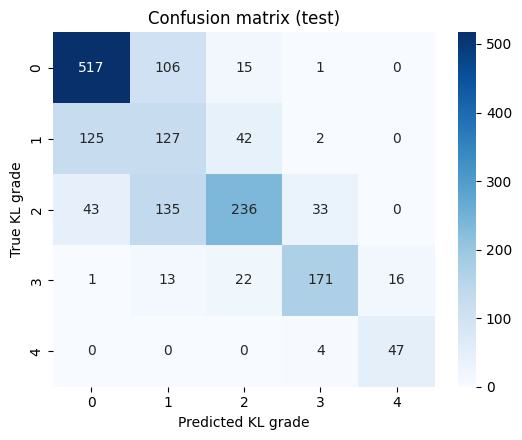

In [8]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, cohen_kappa_score)

os.makedirs("mufsal_outputs", exist_ok=True)

@torch.no_grad()
def get_logits(loader):
    model.eval()
    L, Y = [], []
    for x, y in loader:
        L.append(model(x.to(device)).float().cpu())
        Y.append(y)
    return torch.cat(L), torch.cat(Y)

test_logits, test_y = get_logits(test_loader)
pred = test_logits.argmax(1).numpy()
y = test_y.numpy()

print(f"Test accuracy  : {accuracy_score(y, pred):.4f}")
print(f"Macro F1       : {f1_score(y, pred, average='macro'):.4f}")
print(f"Quadratic kappa: {cohen_kappa_score(y, pred, weights='quadratic'):.4f}\n")
print(classification_report(y, pred, target_names=[f"KL-{g}" for g in train.classes], digits=3))

cm = confusion_matrix(y, pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=train.classes, yticklabels=train.classes)
plt.xlabel("Predicted KL grade"); plt.ylabel("True KL grade"); plt.title("Confusion matrix (test)")
plt.tight_layout()
plt.savefig("mufsal_outputs/confusion_matrix.png", dpi=150)
plt.show()

## Confidence calibration (Temperature Scaling) + save final model

In [9]:
import torch.nn.functional as F

val_logits, val_y = get_logits(val_loader)

log_T = torch.zeros(1, requires_grad=True)
lbfgs = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)
def closure():
    lbfgs.zero_grad()
    loss = F.cross_entropy(val_logits / log_T.exp(), val_y)
    loss.backward()
    return loss
lbfgs.step(closure)
T = log_T.exp().item()
print(f"Learned temperature T = {T:.3f}")

def ece(probs, labels, bins=10):
    conf, p = probs.max(1)
    acc = (p == labels).float()
    edges = torch.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (acc[m].mean() - conf[m].mean()).abs()
    return float(e)

print(f"ECE before calibration: {ece(F.softmax(test_logits, 1), test_y):.4f}")
print(f"ECE after  calibration: {ece(F.softmax(test_logits / T, 1), test_y):.4f}")

torch.save({"state_dict": model.state_dict(), "temperature": T,
            "classes": train.classes, "img_size": 224,
            "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225],
            "denoise": USE_DENOISE},
           "mufsal_outputs/mufsal_densenet169.pt")
print("Saved to mufsal_outputs/  (download it from the Files panel)")

Learned temperature T = 1.020
ECE before calibration: 0.0376
ECE after  calibration: 0.0382
Saved to mufsal_outputs/  (download it from the Files panel)
